# 第4章 W-H1储热动态辨识与状态估计

沿用书稿数据协议：全部轨迹由方程构造。先在仓库根目录安装 requirements.txt 与 requirements-viz.txt；本笔记还需 Jupyter/IPython。每次执行使用临时输出目录。完整交互演示在 demo/ch04/教学演示.html。

In [1]:
from pathlib import Path
import sys, tempfile, json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "chapters/ch04/run.py").exists())
sys.path.insert(0, str(root / "chapters/ch04"))
import run as wh1
work = tempfile.TemporaryDirectory(prefix="wh1_notebook_")
out = Path(work.name) / "experiment"
summary = wh1.run(out)
data = json.loads((out / "experiment.json").read_text(encoding="utf-8"))
print("完整轨迹：", len(data["episodes"]), "温度记录：", sum(len(e["truth"]) for e in data["episodes"]))

{
  "out": "/var/folders/8x/0jq7cy3x47ng4x3_6bnrqj5w0000gn/T/wh1_notebook_q_q70tnk/experiment",
  "capacity": 417.97478016470495,
  "ua": 0.009997189164056026,
  "beta": 0.00011994151676641496,
  "q": {
    "physical": 1e-05,
    "gray": 0
  },
  "test_rmse": {
    "test_nominal": {
      "measurement": 0.24118,
      "physical": 0.1459,
      "gray": 3.65417,
      "kf": 0.01718,
      "ekf": 3.23128
    },
    "test_loss": {
      "measurement": 0.24448,
      "physical": 5.28147,
      "gray": 0.09988,
      "kf": 2.08155,
      "ekf": 0.01049
    },
    "test_bias": {
      "measurement": 1.01745,
      "physical": 5.28147,
      "gray": 0.09988,
      "kf": 2.71223,
      "ekf": 0.08377
    },
    "test_hot": {
      "measurement": 0.24825,
      "physical": 12.2045,
      "gray": 0.56393,
      "kf": 3.87762,
      "ekf": 0.35828
    }
  }
}
完整轨迹： 10 温度记录： 5410


## 1 从能量平衡核验解析递推

预测用解析式，参考用独立DOP853。观察一次120 s和两次60 s得到相同末温。

In [2]:
one = wh1.linear_step(38, 2, 20, 418, .01, 120)
half = wh1.linear_step(38, 2, 20, 418, .01, 60)
two = wh1.linear_step(half, 2, 20, 418, .01, 60)
assert abs(one - two) < 1e-12
print(f"120 s末温：{one:.9f} ℃；分段差：{abs(one-two):.3e} K")

120 s末温：38.521738773 ℃；分段差：0.000e+00 K


## 2 阅读参数与不确定性

区间采用正确模型、独立同方差噪声下的局部近似。现场功率误差与结构误差需另行纳入模型。

In [3]:
fit = summary["physical_fit"]
print(f"C = {fit['capacity']:.6f} kJ/K; UA = {fit['ua']:.9f} kW/K")
print("C区间：", fit["ci95"][0], "UA区间：", fit["ci95"][1])
print("残差β：", summary["beta_fitted"], "选择的Q：", summary["chosen_q"])

C = 417.974780 kJ/K; UA = 0.009997189 kW/K
C区间： [417.4193224834688, 418.5302378459411] UA区间： [0.009988509293164388, 0.010005869034947663]
残差β： 0.00011994151676641496 选择的Q： {'physical': 1e-05, 'gray': 0}


## 3 重绘参数图并查看真实计算结果

绘图脚本只读取已保存实验输出。SVG保留可编辑文字，PNG为600 dpi。

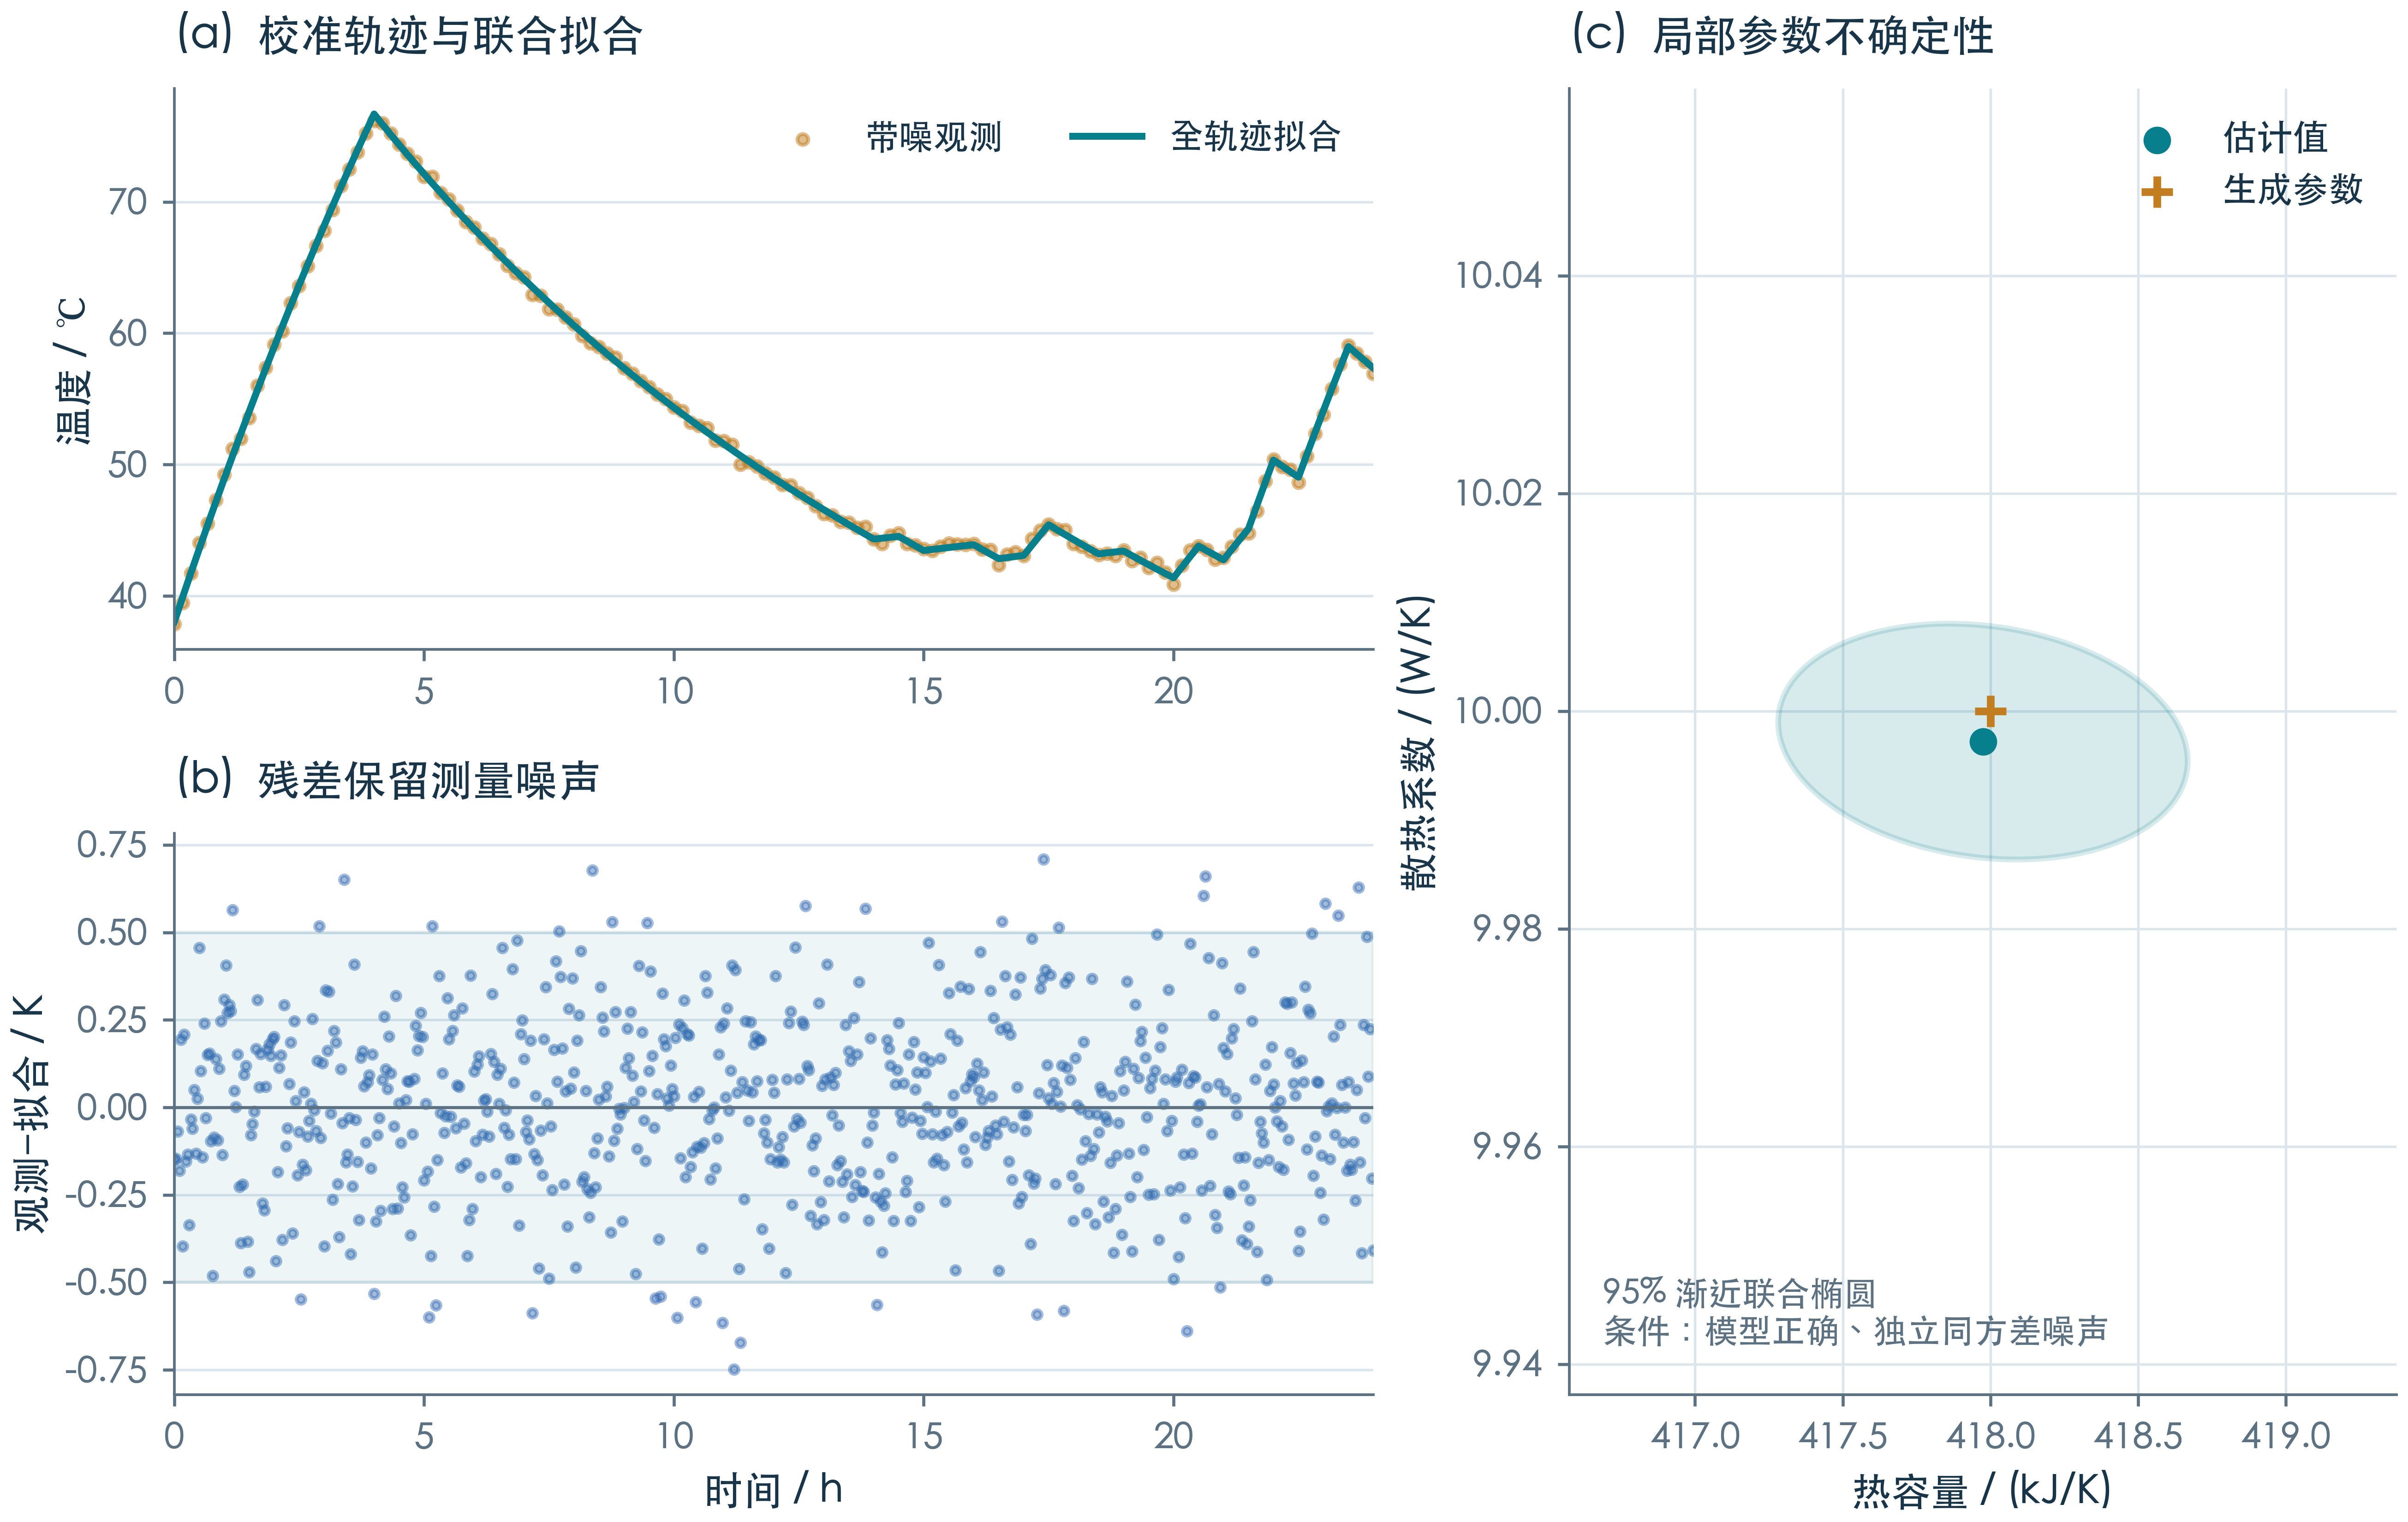

In [4]:
from plot_results import plot
from IPython.display import Image, display
plot(out / "experiment.json", out / "figures")
display(Image(filename=str(out / "figures/fig4_5_parameter_fit.png"), width=850))

## 4 同时保留改善与退化

逐行对比常规、附加散热、偏移和高温，不将共享轨迹的偏移对照计作独立重复实验。

In [5]:
for case, metrics in summary["metrics"].items():
    print(case, {m: round(v["rmse_C"], 4) for m, v in metrics.items()})
print("附加散热EKF覆盖率：", summary["metrics"]["test_loss"]["ekf"]["coverage95_percent"])
print("传感器偏移EKF覆盖率：", summary["metrics"]["test_bias"]["ekf"]["coverage95_percent"])

test_nominal {'measurement': 0.2412, 'physical': 0.1459, 'gray': 3.6542, 'kf': 0.0172, 'ekf': 3.2313}
test_loss {'measurement': 0.2445, 'physical': 5.2815, 'gray': 0.0999, 'kf': 2.0815, 'ekf': 0.0105}
test_bias {'measurement': 1.0174, 'physical': 5.2815, 'gray': 0.0999, 'kf': 2.7122, 'ekf': 0.0838}
test_hot {'measurement': 0.2482, 'physical': 12.2045, 'gray': 0.5639, 'kf': 3.8776, 'ekf': 0.3583}
附加散热EKF覆盖率： 80.0376647834275
传感器偏移EKF覆盖率： 33.70998116760829


## 5 课堂延伸

双击离线演示，改变C、UA、噪声、传感器偏移和Q。导出CSV比较6 h前后的误差；导出SVG用于报告。参考热量核验采用开环轨迹，滤波校正单独作为信息更新记录。

复现检查：`python chapters/ch04/verify.py`；浏览器数值一致性：`node --test tests/ch04.test.cjs`。